In [5]:
!mkdir -p /root/.kaggle
!cp /content/kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [6]:
!kaggle datasets download kevinsmith94624/crop-yield-production

Dataset URL: https://www.kaggle.com/datasets/kevinsmith94624/crop-yield-production
License(s): Community Data License Agreement - Sharing - Version 1.0


In [7]:
!unzip /content/crop-yield-production.zip -d /content

Archive:  /content/crop-yield-production.zip
  inflating: /content/Crop_recommendation.csv  
  inflating: /content/dataset-metadata.json  


In [129]:
import pandas as pd


df = pd.read_csv("/content/Crop_recommendation.csv")
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [130]:
df.columns = ["N",	"P" ,	"K",	"temperature",	"humidity",	"ph",	"rainfall","crop"]

In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   crop         2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [132]:
def label_problems(row):
    issues = []
    if row["N"] < 20:
        issues.append("Nitrogen Deficiency")
    if row["P"] < 15:
        issues.append("Phosphorus Deficiency")
    if row["K"] < 20:
        issues.append("Potassium Deficiency")
    if row["ph"] < 5.5:
        issues.append("Acidic Soil")
    if row["ph"] > 7.5:
        issues.append("Alkaline Soil")
    if row["rainfall"] < 50:
        issues.append("Drought Conditions")
    if row["rainfall"] > 250:
        issues.append("Excess Rainfall")
    return ", ".join(issues) if issues else "Healthy"

In [133]:
from tqdm import tqdm
problems = []

for index,row in tqdm(df.iterrows(),total=df.shape[0]):
    problems.append(label_problems(row))

100%|██████████| 2200/2200 [00:00<00:00, 15357.44it/s]


In [134]:
df["problems"] = problems
df.head()

,N,P,K,temperature,humidity,ph,rainfall,crop,problems
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,Healthy
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,Healthy
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,"Alkaline Soil, Excess Rainfall"
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,Healthy
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,"Alkaline Soil, Excess Rainfall"


In [135]:
df[["N","P","K","ph","rainfall","problems"]].to_csv("Soil_Contamination.csv",index=False)

In [136]:
def recommend_remedies(row):
    remedies = []

    # Soil-related remedies
    if row["N"] < 20:
        remedies.append("Apply nitrogen-rich fertilizers like urea or ammonium nitrate.")
    if row["P"] < 15:
        remedies.append("Use phosphorus fertilizers such as single superphosphate or bone meal.")
    if row["K"] < 20:
        remedies.append("Apply potassium fertilizers like muriate of potash or sulfate of potash.")
    if row["ph"] < 5.5:
        remedies.append("Add lime to raise soil pH to a neutral level.")
    if row["ph"] > 7.5:
        remedies.append("Incorporate sulfur or organic matter to lower soil pH.")
    if row["rainfall"] < 50:
        remedies.append("Install irrigation systems to ensure adequate water supply.")
    if row["rainfall"] > 250:
        remedies.append("Improve drainage systems or use raised beds to prevent waterlogging.")

    # Temperature and humidity remedies (crop-specific)
    crop = row.get("crop", None)  # Assume crop column exists
    if crop == "wheat":
        if not (10 <= row["temperature"] <= 25):
            remedies.append("Choose wheat varieties suited for extreme temperatures, or shift sowing season.")
        if not (50 <= row["humidity"] <= 70):
            remedies.append("Use dehumidifiers or grow wheat in controlled environments.")
    elif crop == "rice":
        if not (25 <= row["temperature"] <= 35):
            remedies.append("Plant heat-tolerant or cold-tolerant rice varieties as needed.")
        if not (70 <= row["humidity"] <= 90):
            remedies.append("Optimize water management and avoid over-irrigation to control humidity.")

    # Add similar conditions and remedies for other crops as needed

    return ", ".join(remedies) if remedies else "No specific remedies needed"

# Apply the function to each row
df["Recommended_Remedies"] = df.apply(recommend_remedies, axis=1)
df.head()

,N,P,K,temperature,humidity,ph,rainfall,crop,problems,Recommended_Remedies
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,Healthy,Plant heat-tolerant or cold-tolerant rice vari...
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,Healthy,Plant heat-tolerant or cold-tolerant rice vari...
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,"Alkaline Soil, Excess Rainfall",Incorporate sulfur or organic matter to lower ...
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,Healthy,No specific remedies needed
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,"Alkaline Soil, Excess Rainfall",Incorporate sulfur or organic matter to lower ...


In [137]:
def recommend_phyto_remedies(row):
    remedies = []

    # Soil-related phyto-remediation remedies
    if row["N"] < 20:
        remedies.append("Plant legumes such as clover, alfalfa, or beans to naturally fix nitrogen in the soil.")
    if row["P"] < 15:
        remedies.append("Grow phosphate-accumulating plants like buckwheat or lupines to improve phosphorus availability.")
    if row["K"] < 20:
        remedies.append("Use potassium-accumulating plants like sunflower or mustard to enrich soil potassium levels.")
    if row["ph"] < 5.5:
        remedies.append("Plant barley, ryegrass, or oats, which can tolerate acidic soils and help stabilize pH.")
    if row["ph"] > 7.5:
        remedies.append("Grow sulfur-releasing plants like marigolds or sorghum to lower soil alkalinity.")
    if row["rainfall"] < 50:
        remedies.append("Plant drought-tolerant species such as millet, cactus, or vetiver grass to conserve soil moisture.")
    if row["rainfall"] > 250:
        remedies.append("Use water-tolerant plants like willows or reeds to improve drainage and prevent waterlogging.")

    # Temperature and humidity phyto-remediation (crop-specific)
    crop = row.get("crop", None)  # Assume crop column exists
    if crop == "wheat":
        if not (10 <= row["temperature"] <= 25):
            remedies.append("Use heat-resistant wheat varieties like 'CIMMYT Heat Tolerant' or plant shading plants such as trees.")
        if not (50 <= row["humidity"] <= 70):
            remedies.append("Plant cover crops or windbreak species like trees to regulate microclimate humidity.")
    elif crop == "rice":
        if not (25 <= row["temperature"] <= 35):
            remedies.append("Switch to climate-resilient rice varieties or use companion planting with water-shading plants.")
        if not (70 <= row["humidity"] <= 90):
            remedies.append("Plant moisture-absorbing plants like ferns or grasses to regulate humidity in the field.")

    # Add more crop-specific phyto-remediation suggestions as needed

    return ", ".join(remedies) if remedies else "No specific phyto-remediation needed"

# Apply the function to each row
df["Phyto_Remedies"] = df.apply(recommend_phyto_remedies, axis=1)
df.head()


,N,P,K,temperature,humidity,ph,rainfall,crop,problems,Recommended_Remedies,Phyto_Remedies
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,Healthy,Plant heat-tolerant or cold-tolerant rice vari...,Switch to climate-resilient rice varieties or ...
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,Healthy,Plant heat-tolerant or cold-tolerant rice vari...,Switch to climate-resilient rice varieties or ...
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,"Alkaline Soil, Excess Rainfall",Incorporate sulfur or organic matter to lower ...,Grow sulfur-releasing plants like marigolds or...
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,Healthy,No specific remedies needed,No specific phyto-remediation needed
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,"Alkaline Soil, Excess Rainfall",Incorporate sulfur or organic matter to lower ...,Grow sulfur-releasing plants like marigolds or...


In [138]:
# Save the dataset with phyto-remediation remedies
df.to_csv("phyto_remedies_soil_dataset.csv", index=False)

In [139]:
df[["N","P","K","ph","rainfall","problems","Recommended_Remedies"]].to_csv("Recommended_Remedies.csv",index=False)

In [140]:
df = pd.read_csv("/content/Soil_Contamination.csv")
df.head()

,N,P,K,ph,rainfall,problems
0,90,42,43,6.502985,202.935536,Healthy
1,85,58,41,7.038096,226.655537,Healthy
2,60,55,44,7.840207,263.964248,"Alkaline Soil, Excess Rainfall"
3,74,35,40,6.980401,242.864034,Healthy
4,78,42,42,7.628473,262.717340,"Alkaline Soil, Excess Rainfall"


In [141]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   N         2200 non-null   int64  
 1   P         2200 non-null   int64  
 2   K         2200 non-null   int64  
 3   ph        2200 non-null   float64
 4   rainfall  2200 non-null   float64
 5   problems  2200 non-null   object 
dtypes: float64(2), int64(3), object(1)
memory usage: 103.3+ KB


In [142]:
df.describe()

,N,P,K,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,6.469480,103.463655
std,36.917334,32.985883,50.647931,0.773938,54.958389
min,0.000000,5.000000,5.000000,3.504752,20.211267
25%,21.000000,28.000000,20.000000,5.971693,64.551686
50%,37.000000,51.000000,32.000000,6.425045,94.867624
75%,84.250000,68.000000,49.000000,6.923643,124.267508
max,140.000000,145.000000,205.000000,9.935091,298.560117


In [143]:
df["problems"].value_counts()

,count
problems,
Healthy,946
Nitrogen Deficiency,239
Potassium Deficiency,215
Drought Conditions,126
Alkaline Soil,77
Phosphorus Deficiency,68
"Nitrogen Deficiency, Potassium Deficiency",62
"Phosphorus Deficiency, Drought Conditions",55
Acidic Soil,48


In [144]:
id2label = {}
label2id = {}

for index,i in enumerate(df["problems"].unique()):
    id2label[index] = i
    label2id[i] = index

In [145]:
id2label,label2id

({0: 'Healthy',
  1: 'Alkaline Soil, Excess Rainfall',
  2: 'Excess Rainfall',
  3: 'Acidic Soil, Excess Rainfall',
  4: 'Acidic Soil',
  5: 'Alkaline Soil',
  6: 'Potassium Deficiency',
  7: 'Nitrogen Deficiency',
  8: 'Nitrogen Deficiency, Potassium Deficiency',
  9: 'Potassium Deficiency, Acidic Soil',
  10: 'Nitrogen Deficiency, Potassium Deficiency, Acidic Soil',
  11: 'Nitrogen Deficiency, Acidic Soil',
  12: 'Nitrogen Deficiency, Potassium Deficiency, Acidic Soil, Drought Conditions',
  13: 'Acidic Soil, Drought Conditions',
  14: 'Alkaline Soil, Drought Conditions',
  15: 'Nitrogen Deficiency, Potassium Deficiency, Alkaline Soil',
  16: 'Potassium Deficiency, Alkaline Soil, Drought Conditions',
  17: 'Nitrogen Deficiency, Alkaline Soil',
  18: 'Drought Conditions',
  19: 'Nitrogen Deficiency, Acidic Soil, Drought Conditions',
  20: 'Nitrogen Deficiency, Drought Conditions',
  21: 'Nitrogen Deficiency, Potassium Deficiency, Alkaline Soil, Drought Conditions',
  22: 'Potassium De

In [146]:
df["labels"] = df["problems"].apply(lambda x: 0 if x == "Healthy" else 1)
df.head()

,N,P,K,ph,rainfall,problems,labels
0,90,42,43,6.502985,202.935536,Healthy,0
1,85,58,41,7.038096,226.655537,Healthy,0
2,60,55,44,7.840207,263.964248,"Alkaline Soil, Excess Rainfall",1
3,74,35,40,6.980401,242.864034,Healthy,0
4,78,42,42,7.628473,262.717340,"Alkaline Soil, Excess Rainfall",1


In [147]:
df.isnull().sum()

,0
N,0
P,0
K,0
ph,0
rainfall,0
problems,0
labels,0


In [148]:
df.head()

,N,P,K,ph,rainfall,problems,labels
0,90,42,43,6.502985,202.935536,Healthy,0
1,85,58,41,7.038096,226.655537,Healthy,0
2,60,55,44,7.840207,263.964248,"Alkaline Soil, Excess Rainfall",1
3,74,35,40,6.980401,242.864034,Healthy,0
4,78,42,42,7.628473,262.717340,"Alkaline Soil, Excess Rainfall",1


In [149]:
df.duplicated().sum()

np.int64(0)

In [150]:
df.drop(["problems"],axis=1).corr().style.background_gradient(cmap="coolwarm")

,N,P,K,ph,rainfall,labels
N,1.000000,-0.231460,-0.140512,0.096683,0.059020,-0.310323
P,-0.231460,1.000000,0.736232,-0.138019,-0.063839,-0.202786
K,-0.140512,0.736232,1.000000,-0.169503,-0.053461,-0.189224
ph,0.096683,-0.138019,-0.169503,1.000000,-0.109069,0.030921
rainfall,0.059020,-0.063839,-0.053461,-0.109069,1.000000,-0.271607
labels,-0.310323,-0.202786,-0.189224,0.030921,-0.271607,1.000000


In [151]:
df.drop(["problems"],axis=1).corr().style.background_gradient(cmap="coolwarm").to_excel("correlation.xlsx")

In [30]:
X = df.drop(["problems","labels","K"],axis=1)
y = df["labels"]

In [31]:
y.value_counts()

,count
labels,
1,1254
0,946


In [32]:
from sklearn.model_selection import train_test_split


X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,shuffle=True
)

In [33]:
X_train.shape,y_train.shape

((1760, 4), (1760,))

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [35]:
from sklearn.ensemble import RandomForestClassifier

base_line_model_1 = RandomForestClassifier(n_estimators=20)
base_line_model_1.fit(X_train_scaled,y_train)

RandomForestClassifier(n_estimators=20)

In [36]:
base_line_model_1.score(X_test_scaled,y_test)

0.8977272727272727

In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test,base_line_model_1.predict(X_test_scaled))
cm

array([[190,  22],
       [ 23, 205]])

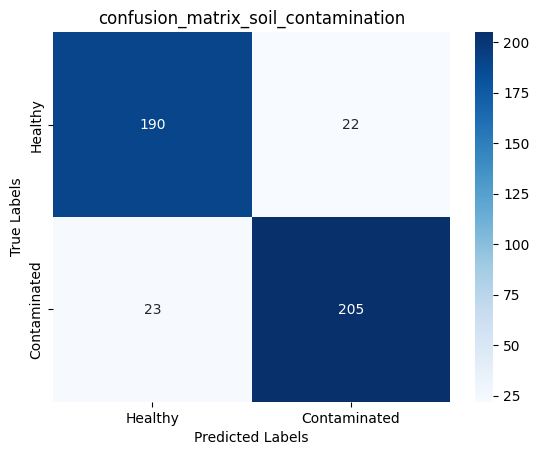

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.title("confusion_matrix_soil_contamination")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.xticks(ticks=[0.5,1.5],labels=["Healthy","Contaminated"])
plt.yticks(ticks=[0.5,1.5],labels=["Healthy","Contaminated"])
plt.show()

### Phyto Remedies

In [39]:
import pandas as pd


df1 = pd.read_csv("/content/phyto_remedies_soil_dataset.csv")
df1.head()

,N,P,K,temperature,humidity,ph,rainfall,crop,problems,Recommended_Remedies,Phyto_Remedies
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,Healthy,Plant heat-tolerant or cold-tolerant rice vari...,Switch to climate-resilient rice varieties or ...
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,Healthy,Plant heat-tolerant or cold-tolerant rice vari...,Switch to climate-resilient rice varieties or ...
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,"Alkaline Soil, Excess Rainfall",Incorporate sulfur or organic matter to lower ...,Grow sulfur-releasing plants like marigolds or...
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,Healthy,No specific remedies needed,No specific phyto-remediation needed
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,"Alkaline Soil, Excess Rainfall",Incorporate sulfur or organic matter to lower ...,Grow sulfur-releasing plants like marigolds or...


In [40]:
df["Phyto_remedies"] = df1["Phyto_Remedies"]

In [41]:
counts_1 = df["Phyto_remedies"].value_counts().reset_index()

In [42]:
selected_remedies = counts_1[counts_1["count"]> 50]["Phyto_remedies"].tolist()

In [43]:
selected_remedies.append('Grow sulfur-releasing plants like marigolds or sorghum to lower soil alkalinity.')

In [44]:
import numpy as np
df["Phyto_remedies"] = [i if i in selected_remedies else np.nan for i in  df["Phyto_remedies"].tolist()]

In [45]:
df.isnull().sum()

,0
N,0
P,0
K,0
ph,0
rainfall,0
problems,0
labels,0
Phyto_remedies,448


In [46]:
df.dropna(inplace=True)

In [47]:
df["Phyto_remedies"] = df["Phyto_remedies"].apply(lambda x: x.split(",")[0])

In [48]:
df["Phyto_remedies"].replace({
    'Use potassium-accumulating plants like sunflower or mustard to enrich soil potassium levels.':'Grow sulfur-releasing plants like marigolds or sorghum to lower soil alkalinity.'
},inplace=True)

<ipython-input-48-3824c9bbb0fe>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Phyto_remedies"].replace({


In [49]:
df["Phyto_remedies"].value_counts(),df["labels"].value_counts()

(Phyto_remedies
 No specific phyto-remediation needed                                                                913
 Plant legumes such as clover                                                                        301
 Grow sulfur-releasing plants like marigolds or sorghum to lower soil alkalinity.                    289
 Plant drought-tolerant species such as millet                                                       126
 Grow phosphate-accumulating plants like buckwheat or lupines to improve phosphorus availability.    123
 Name: count, dtype: int64,
 labels
 0    913
 1    839
 Name: count, dtype: int64)

In [50]:
id2label = {}
label2id = {}

for index,i in enumerate(df["Phyto_remedies"].unique()):
    id2label[index] = i
    label2id[i] = index

In [51]:
df["remedies"] = df["Phyto_remedies"].map(label2id)

In [52]:
X = df.drop(["problems","Phyto_remedies"],axis=1)
y = df["Phyto_remedies"].map(label2id)

In [53]:
y.value_counts()

,count
Phyto_remedies,
0,913
2,301
1,289
3,126
4,123


In [54]:
X.corr().style.background_gradient(cmap="coolwarm")

,N,P,K,ph,rainfall,labels,remedies
N,1.000000,-0.325126,-0.250323,0.128173,-0.097245,-0.225029,-0.090628
P,-0.325126,1.000000,0.767045,-0.201351,-0.041660,-0.173839,-0.324489
K,-0.250323,0.767045,1.000000,-0.221541,-0.102124,-0.104546,-0.048448
ph,0.128173,-0.201351,-0.221541,1.000000,-0.065179,0.043209,-0.084644
rainfall,-0.097245,-0.041660,-0.102124,-0.065179,1.000000,-0.328720,-0.332120
labels,-0.225029,-0.173839,-0.104546,0.043209,-0.328720,1.000000,0.825736
remedies,-0.090628,-0.324489,-0.048448,-0.084644,-0.332120,0.825736,1.000000


In [65]:
X = df.drop(["problems","labels","Phyto_remedies","K","remedies"],axis=1)
y = df["remedies"]

In [66]:
from sklearn.model_selection import train_test_split


X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,shuffle=True,stratify=y
)

In [67]:
y_train.value_counts(),y_test.value_counts()

(remedies
 0    730
 2    241
 1    231
 3    101
 4     98
 Name: count, dtype: int64,
 remedies
 0    183
 2     60
 1     58
 3     25
 4     25
 Name: count, dtype: int64)

In [68]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [79]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=20)
model.fit(X_train_scaled,y_train)

RandomForestClassifier(n_estimators=20)

In [80]:
model.score(X_test_scaled,y_test)

0.8888888888888888

In [81]:
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test.values,model.predict(X_test_scaled))

In [82]:
id2label[1],id2label[2],id2label[0]

('Grow sulfur-releasing plants like marigolds or sorghum to lower soil alkalinity.',
 'Plant legumes such as clover',
 'No specific phyto-remediation needed')

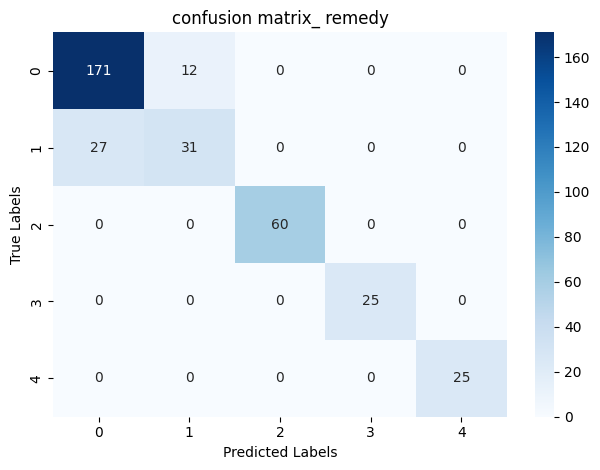

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.title("confusion matrix_ remedy")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.tight_layout()
plt.show()

### Data Modeling

In [86]:
df.head()

,N,P,K,ph,rainfall,problems,labels,Phyto_remedies,remedies
3,74,35,40,6.980401,242.864034,Healthy,0,No specific phyto-remediation needed,0
14,94,50,37,6.948020,209.586971,Healthy,0,No specific phyto-remediation needed,0
34,88,54,44,6.149411,233.132137,Healthy,0,No specific phyto-remediation needed,0
35,95,55,42,5.950661,193.347399,Healthy,0,No specific phyto-remediation needed,0
41,64,45,43,5.534878,209.900198,Healthy,0,No specific phyto-remediation needed,0


In [87]:
df["remedies"].value_counts(),df["labels"].value_counts()

(remedies
 0    913
 2    301
 1    289
 3    126
 4    123
 Name: count, dtype: int64,
 labels
 0    913
 1    839
 Name: count, dtype: int64)

In [88]:
X = df.drop(["problems","labels","Phyto_remedies","K","remedies"],axis=1)
y_h = df["labels"]
y_r = df["remedies"]

In [89]:
y = y_h.astype(str)+","+y_r.astype(str)

In [90]:
y.value_counts()

,count
"0,0",913
"1,2",301
"1,1",289
"1,3",126
"1,4",123


In [91]:
from imblearn.over_sampling import SMOTE


smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

In [92]:
y_resampled.value_counts()

,count
"0,0",913
"1,1",913
"1,2",913
"1,3",913
"1,4",913


In [93]:
y_resampled = pd.DataFrame(y_resampled,columns=["labels"])

In [94]:
y_resampled = y_resampled["labels"].str.split(",",expand=True)
y_resampled.columns = ["labels","remedies"]
y_resampled.head()

,labels,remedies
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


In [95]:
df = pd.concat([X_resampled,y_resampled],axis=1)
df.head()

,N,P,ph,rainfall,labels,remedies
0,74,35,6.980401,242.864034,0,0
1,94,50,6.948020,209.586971,0,0
2,88,54,6.149411,233.132137,0,0
3,95,55,5.950661,193.347399,0,0
4,64,45,5.534878,209.900198,0,0


In [96]:
df.to_csv("DataSet.csv",index=False)

### MOE - for Dynamic weighting for FT-Transformer

In [97]:
X = df.drop(["labels","remedies"],axis=1)
y_h = df["labels"].astype(int)
y_r = df["remedies"].astype(int)

In [98]:
from sklearn.model_selection import train_test_split


X_train,X_test,y_h_train,y_h_test,y_r_train,y_r_test = train_test_split(
    X,y_h,y_r,test_size=0.2,random_state=42,shuffle=True,stratify=y_h
)

In [99]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [100]:
y_r_train.value_counts(),y_h_test.value_counts()

(remedies
 3    750
 1    742
 0    730
 4    716
 2    714
 Name: count, dtype: int64,
 labels
 1    730
 0    183
 Name: count, dtype: int64)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
from tensorflow.keras.saving import register_keras_serializable

# MoE Layer
@register_keras_serializable(package='Custom', name='MoELayer')
class MoELayer():
    def __init__(self, num_experts, expert_dim, embed_dim, top_k=2, **kwargs):
        super(MoELayer, self).__init__(**kwargs)
        self.num_experts = num_experts
        self.top_k = int(top_k)
        self.expert_dim = expert_dim
        self.embed_dim = embed_dim
        self.experts = [tf.keras.Sequential([
            layers.Dense(expert_dim, activation='relu'),
            layers.Dense(embed_dim)
        ]) for _ in range(num_experts)]
        self.gate = layers.Dense(num_experts, activation=None)

    def build(self, input_shape):
        self.gate.build(input_shape)
        for expert in self.experts:
            expert.build(input_shape)
        self.built = True

    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]
        seq_len = tf.shape(inputs)[1]

        gate_scores = self.gate(inputs)
        gate_scores = tf.nn.softmax(gate_scores, axis=-1)
        top_k_scores, top_k_indices = tf.nn.top_k(gate_scores, k=self.top_k)
        top_k_scores = tf.nn.softmax(top_k_scores, axis=-1)

        outputs = tf.zeros((batch_size, seq_len, self.embed_dim), dtype=inputs.dtype)

        for i in range(self.num_experts):
            for k in range(self.top_k):
                k_mask = tf.equal(top_k_indices[:, :, k], i)
                k_mask = tf.expand_dims(k_mask, axis=-1)
                k_mask = tf.repeat(k_mask, self.embed_dim, axis=-1)
                expert_input = tf.where(k_mask, inputs, tf.zeros_like(inputs))
                expert_output = self.experts[i](expert_input)
                gate_weight = tf.where(top_k_indices[:, :, k:k+1] == i, top_k_scores[:, :, k:k+1], tf.zeros_like(top_k_scores[:, :, k:k+1]))
                gate_weight = tf.repeat(gate_weight, self.embed_dim, axis=-1)
                outputs += expert_output * gate_weight

        return outputs

    def compute_output_shape(self, input_shape):
        return (*input_shape[:-1], self.embed_dim)

    def get_config(self):
        config = super().get_config()
        config.update({
            'num_experts': self.num_experts,
            'expert_dim': self.expert_dim,
            'embed_dim': self.embed_dim,
            'top_k': self.top_k
        })
        return config

# Transformer Block
@register_keras_serializable(package='Custom', name='TransformerBlock')
class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, num_experts, expert_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.moe = MoELayer(num_experts, expert_dim, embed_dim, top_k=2)
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, inputs):
        attn_output = self.attention(inputs, inputs)
        attn_output = self.dropout1(attn_output)
        out1 = self.layernorm1(inputs + attn_output)
        moe_output = self.moe(out1)
        moe_output = self.dropout2(moe_output)
        return self.layernorm2(out1 + moe_output)

    def get_config(self):
        config = super().get_config()
        config.update({
            'embed_dim': self.attention.key_dim,
            'num_heads': self.attention.num_heads,
            'num_experts': self.moe.num_experts,
            'expert_dim': self.moe.expert_dim,
            'dropout_rate': self.dropout1.rate,
        })
        return config

# Dynamic Loss Weight Callback
@register_keras_serializable(package='Custom', name='DynamicLossWeightCallback')
class DynamicLossWeightCallback(tf.keras.callbacks.Callback):
    def __init__(self, loss_weights, loss_names):
        super().__init__()
        self.loss_weights = loss_weights
        self.loss_names = loss_names
        self.loss_history = {name: [] for name in loss_names}

    def on_epoch_end(self, epoch, logs=None):
        for name in self.loss_names:
            self.loss_history[name].append(logs.get(name, 0.0))
        avg_losses = [np.mean(self.loss_history[name][-1:]) for name in self.loss_names]
        total_loss = sum(avg_losses) + 1e-8
        new_weights = [loss / total_loss for loss in avg_losses]
        weight_sum = sum(new_weights)
        if weight_sum > 0:
            for i, name in enumerate(self.loss_names):
                self.loss_weights[name] = new_weights[i] / weight_sum
        print(f"Epoch {epoch+1}: Updated loss weights - {self.loss_weights}")

    def get_config(self):
        return {'loss_weights': self.loss_weights, 'loss_names': self.loss_names}

# FT-Transformer Model
def ft_transformer(input_dim, num_classes_0, num_classes_1, embed_dim=32, num_heads=4, num_experts=4, expert_dim=64, num_layers=4, dropout_rate=0.1):
    inputs = layers.Input(shape=(input_dim,))
    x = layers.Dense(embed_dim)(inputs)
    x = layers.Reshape((1, embed_dim))(x)
    for _ in range(num_layers):
        x = TransformerBlock(embed_dim, num_heads, num_experts, expert_dim, dropout_rate)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    output_1 = layers.Dense(num_classes_0, activation='sigmoid', name='health_check')(x)
    output_2 = layers.Dense(num_classes_1, activation='softmax', name='remedy_recommendation')(x)
    return models.Model(inputs, [output_1, output_2])

# Assuming you already have the following variables:
# X_train, y_h_train (binary), y_r_train (int labels for multi-class)
num_classes_0 = 1
num_classes_1 = len(np.unique(y_r_train))

model = ft_transformer(
    input_dim=X_train.shape[1],
    num_classes_0=num_classes_0,
    num_classes_1=num_classes_1
)

loss_weights = {'health_check': 0.5, 'remedy_recommendation': 0.5}
model.compile(
    optimizer='adam',
    loss={'health_check': 'binary_crossentropy', 'remedy_recommendation': 'sparse_categorical_crossentropy'},
    loss_weights=loss_weights,
    metrics={'health_check': 'accuracy', 'remedy_recommendation': 'accuracy'}
)

# Model Summary
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 4)]          0           []                               
                                                                                                  
 dense (Dense)                  (None, 32)           160         ['input_1[0][0]']                
                                                                                                  
 reshape (Reshape)              (None, 1, 32)        0           ['dense[0][0]']                  
                                                                                                  
 transformer_block (Transformer  (None, 1, 32)       33828       ['reshape[0][0]']                
 Block)                                                                                       

In [10]:
!pip install pydot graphviz

In [ ]:
from tensorflow.keras.utils import plot_model


plot_model(model,show_shapes=True,show_layer_names=True,dpi=75,to_file="model.png")

In [107]:
# Dynamic loss weight callback
dynamic_weight_callback = DynamicLossWeightCallback(
    loss_weights=loss_weights,
    loss_names=['health_check_loss', 'remedy_recommendation_loss']
)

# Train the model
history = model.fit(
    X_train_scaled, {'health_check': y_h_train, 'remedy_recommendation': y_r_train},
    epochs=200,
    batch_size=128,
    validation_data=(X_test_scaled, {'health_check': y_h_test, 'remedy_recommendation': y_r_test}),
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=50, restore_best_weights=True),
        dynamic_weight_callback,
        tf.keras.callbacks.ModelCheckpoint(filepath="model.keras",monitor="val_remedy_recommendation_accuracy",save_best_only=True,verbose=1)
    ],
    verbose=1
)

# Evaluate the model
val_metrics = model.evaluate(
    X_test_scaled,
    {'health_check': y_h_test, 'remedy_recommendation': y_r_test},
    verbose=0
)
print(f"Test Health Check Accuracy: {val_metrics[3]:.4f}")
print(f"Test Remedy Recommendation Accuracy: {val_metrics[4]:.4f}")


Epoch 1/200
28/29 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - health_check_accuracy: 0.7981 - health_check_loss: 0.4792 - loss: 0.8902 - remedy_recommendation_accuracy: 0.4786 - remedy_recommendation_loss: 1.3012Epoch 1: Updated loss weights - {'health_check': 0.5, 'remedy_recommendation': 0.5, 'health_check_loss': np.float64(0.2881835942324845), 'remedy_recommendation_loss': np.float64(0.7118164057675156)}

Epoch 1: val_remedy_recommendation_accuracy improved from -inf to 0.79080, saving model to model.keras
29/29 ━━━━━━━━━━━━━━━━━━━━ 42s 238ms/step - health_check_accuracy: 0.8006 - health_check_loss: 0.4744 - loss: 0.8782 - remedy_recommendation_accuracy: 0.4872 - remedy_recommendation_loss: 1.2818 - val_health_check_accuracy: 0.8686 - val_health_check_loss: 0.3297 - val_loss: 0.4777 - val_remedy_recommendation_accuracy: 0.7908 - val_remedy_recommendation_loss: 0.5877
Epoch 2/200
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - health_check_accuracy: 0.8858 - health_check_loss: 0.3180 - loss: 0.472

In [111]:
# Correct way to call model.evaluate with multiple outputs
model.evaluate(X_test_scaled, {'health_check': y_h_test, 'remedy_recommendation': y_r_test})

29/29 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - health_check_accuracy: 0.9328 - health_check_loss: 0.2017 - loss: 0.2073 - remedy_recommendation_accuracy: 0.9327 - remedy_recommendation_loss: 0.2128


[0.1816546767950058,
 0.17640547454357147,
 0.18404358625411987,
 0.9342826008796692,
 0.932092010974884]

In [109]:
from tensorflow.keras.models import load_model


model = load_model("/content/model.keras")

/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:393: UserWarning: `build()` was called on layer 'transformer_block_4', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:393: UserWarning: `build()` was called on layer 'transformer_block_5', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:393: UserWarning: `build()` was called on layer 'transformer_block_6', how

In [112]:
prediction_0,prediction_1 = model.predict(X_test_scaled)

29/29 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step


In [113]:
prediction_1.shape,np.argmax(prediction_1,axis=1).shape

((913, 5), (913,))

In [114]:
y_pred_0 = np.where(prediction_0 > 0.5,1,0)
y_pred_1 = np.argmax(prediction_1,axis=1)

In [115]:
from sklearn.metrics import confusion_matrix,classification_report


print("classification report : \n",classification_report(
    y_h_test.values,y_pred_0
))

classification report : 
               precision    recall  f1-score   support

           0       0.89      0.77      0.82       183
           1       0.94      0.98      0.96       730

    accuracy                           0.93       913
   macro avg       0.92      0.87      0.89       913
weighted avg       0.93      0.93      0.93       913



In [116]:
from sklearn.metrics import confusion_matrix,classification_report


print("classification report : \n",classification_report(
    y_r_test.values,y_pred_1
))

classification report : 
               precision    recall  f1-score   support

           0       0.89      0.77      0.82       183
           1       0.79      0.90      0.84       171
           2       0.99      0.99      0.99       199
           3       0.99      1.00      1.00       163
           4       0.99      1.00      1.00       197

    accuracy                           0.93       913
   macro avg       0.93      0.93      0.93       913
weighted avg       0.93      0.93      0.93       913



In [117]:
output = {
    "remedies_prediction":prediction_1.tolist(),
    "health_prediction":prediction_0.tolist(),
    "Actual_Healt":y_h_test.tolist(),
    "Actual_Remedies":y_r_test.tolist(),
}

In [118]:
import json


with open("output.json","w") as f:
    json.dump(output,f)

In [119]:
histories = {
    "health_check":
    {
        "accuracy":
        {
            "train":history.history["health_check_accuracy"],
            "val":history.history["val_health_check_accuracy"]
        },
        "loss":
        {
            "train":history.history["health_check_loss"],
            "val":history.history["val_health_check_loss"]
        }
    },
    "remedy":{
        "accuracy":
        {
            "train":history.history["remedy_recommendation_accuracy"],
            "val":history.history["val_remedy_recommendation_accuracy"]
        },
        "loss": {
            "train": history.history["remedy_recommendation_loss"],
            "val": history.history["val_remedy_recommendation_loss"]
        }

    }

}

In [120]:
with open("history.json","w") as f:
    json.dump(histories,f)

In [122]:
with open("label2id.json","w") as f:
    json.dump(label2id,f)

In [123]:
with open("id2label.json","w") as f:
    json.dump(id2label,f)

In [124]:
import pickle

with open("scaler.pkl","wb") as f:
    pickle.dump(scaler,f)

In [163]:
with open("features.json","w") as f:
    json.dump({"features":list(X_train.columns)},f)

### Inference

In [201]:
import pickle
import json
import tensorflow as tf
import numpy as np

with open("scaler.pkl","rb") as f:
    scaler = pickle.load(f)

model = tf.keras.models.load_model("/content/model.keras")

with open("label2id.json","r") as f:
    label2id = json.load(f)

with open("id2label.json","r") as f:
    id2label = json.load(f)

with open("features.json","r") as f:
    features = json.load(f)
def inference_pipeline(inputs):
  if type(inputs) == list:
    inputs = np.array(list)
  if type(inputs) == pd.core.series.Series:
    inputs = inputs[features["features"]]

  if inputs.ndim == 1:
    inputs = np.array(inputs).reshape(1,-1)

  inputs = scaler.transform(inputs)
  prediction_0,prediction_1 = model.predict(inputs)
  y_pred_0 = np.where(prediction_0 > 0.5,1,0)
  y_pred_1 = np.argmax(prediction_1,axis=1)

  return {
      "Health Check": "UnHealthy" if y_pred_0[0] > 0 else "Healthy",
      "Remedy Recommendation": id2label[str(y_pred_1[0].tolist())]
  }

/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:393: UserWarning: `build()` was called on layer 'transformer_block_4', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:393: UserWarning: `build()` was called on layer 'transformer_block_5', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:393: UserWarning: `build()` was called on layer 'transformer_block_6', how

In [202]:
id2label

{'0': 'No specific phyto-remediation needed',
 '1': 'Grow sulfur-releasing plants like marigolds or sorghum to lower soil alkalinity.',
 '2': 'Plant legumes such as clover',
 '3': 'Plant drought-tolerant species such as millet',
 '4': 'Grow phosphate-accumulating plants like buckwheat or lupines to improve phosphorus availability.'}

In [203]:
X_test.values[3].reshape(-1,1).shape

(4, 1)

In [208]:
inference_pipeline(X_test.values[2])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


{'Health Check': 'Healthy',
 'Remedy Recommendation': 'No specific phyto-remediation needed'}